# Reusable LISA Link Simulation Example

This notebook shows how to call the LISA link simulation from user-provided waveform arrays. The full run creates a realistic LISA orbit, six GW links, lisainstrument noisy links, noisy XYZ/AET TDI, GW-only XYZ/AET TDI in Hz, and overlay plots.

The default configuration uses a `100000 s` science segment so the `1e-5 Hz` low-frequency cut is represented by the first FFT bin. The full noisy instrument run can take several minutes and writes large CSV/HDF5 files.

In [ ]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "scripts":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.lisa_link_simulation import LisaLinkSimulationConfig, load_npz_waveform, run_lisa_link_simulation

PROJECT_ROOT

## Define Or Load A Waveform

Replace this cell with your own waveform if needed. The LISA link simulation expects strictly increasing `t` values in seconds and matching `hplus`, `hcross` strain arrays.

In [ ]:
waveform_file = PROJECT_ROOT / "lisa_link_sim" / "inputs" / "my_waveform.npz"
t, hplus, hcross = load_npz_waveform(waveform_file)

# To use your own waveform instead, define arrays directly:
# t = ...       # seconds, strictly increasing
# hplus = ...   # strain
# hcross = ...  # strain

print(f"N = {len(t)}")
print(f"dt = {(t[1] - t[0]):.6g} s")
print(f"t range = [{t.min():.6g}, {t.max():.6g}] s")
print(f"max strain = {((hplus**2 + hcross**2)**0.5).max():.3e}")

## Run The Link Simulation

Outputs are written under `lisa_link_sim/script_run/` so the original notebook outputs are left untouched.

In [ ]:
config = LisaLinkSimulationConfig(
    dt=0.1,
    science_duration=100_000.0,
    burn_in_seconds=600.0,
    frequency_low_hz=1e-5,
    frequency_high_hz=1e-2,
    orbit_duration_factor=5.0,
    orbit_dt=600.0,
    central_freq_hz=2.816e14,
    seed=12345,
)

products = run_lisa_link_simulation(
    t,
    hplus,
    hcross,
    work_dir=PROJECT_ROOT / "lisa_link_sim" / "script_run",
    config=config,
    make_plots=True,
)

products.diagnostics

## Output Files

In [ ]:
for name, path in products.paths.__dict__.items():
    if name.endswith(("csv", "h5", "npz", "plot")):
        print(f"{name:24s} {path}")

## Quick Plot

Plot one noisy TDI channel against the Hz-converted GW-only signal. The cell downsamples for display only; the CSV files keep all samples.

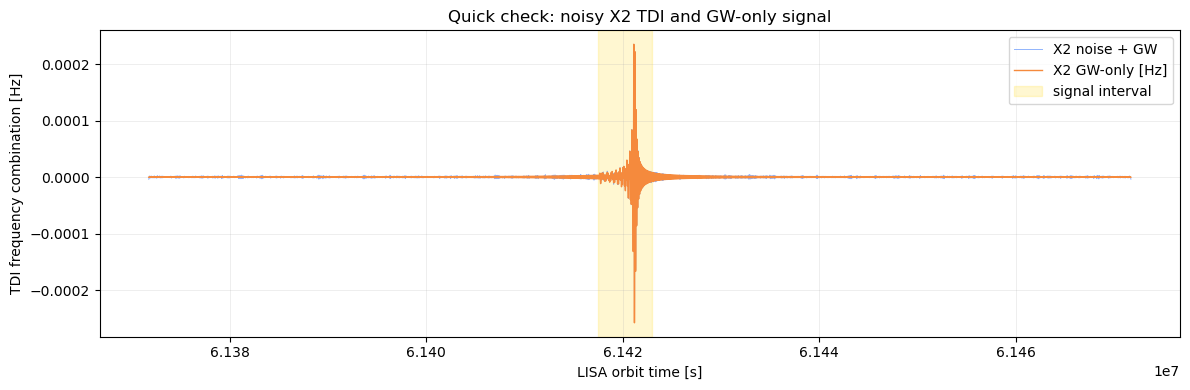

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

noisy = pd.read_csv(products.paths.noisy_tdi_csv, usecols=["t_lisa", "X2"])
gw_only = pd.read_csv(products.paths.gw_tdi_csv, usecols=["t_lisa", "X2_gw_hz"])

stride = max(1, len(noisy) // 20_000)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(noisy["t_lisa"].iloc[::stride], noisy["X2"].iloc[::stride], lw=0.7, alpha=0.65, label="X2 noise + GW")
ax.plot(gw_only["t_lisa"].iloc[::stride], gw_only["X2_gw_hz"].iloc[::stride], lw=1.0, label="X2 GW-only [Hz]")

start = products.diagnostics.get("xyz_signal_start_lisa")
stop = products.diagnostics.get("xyz_signal_stop_lisa")
if start is not None and stop is not None:
    ax.axvspan(start, stop, color="gold", alpha=0.18, label="signal interval")

ax.set_xlabel("LISA orbit time [s]")
ax.set_ylabel("TDI frequency combination [Hz]")
ax.set_title("Quick check: noisy X2 TDI and GW-only signal")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
